In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from math import pi

# 1. Configuración estética académica general
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'axes.spines.top': False,  # Quita el borde de arriba
    'axes.spines.right': False # Quita el borde de la derecha
})

# 2. Cargar datos
df = pd.read_csv("resultados_finales_v2.csv")

# 3. Forzar tipo numérico en las columnas necesarias por si acaso
score_cols = [
    'juez_p1_andamiaje', 'juez_p1_coherencia', 
    'juez_p2_andamiaje', 'juez_p2_coherencia',
    'juez_medio_integracion', 'juez_bajo_integracion', 
    'juez_fidelidad'
]
sim_cols = [
    'sim_pista_1', 'sim_pista_2', 
    'sim_enunciado_medio', 'sim_enunciado_bajo'
]


df['sim_global'] = df[sim_cols].mean(axis=1)

for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
df['tiempo_respuesta'] = pd.to_numeric(df['tiempo_respuesta'], errors='coerce')

# 4. Crear una súper-métrica: Nota Media Global del Juez
df['nota_global_juez'] = df[score_cols].mean(axis=1)

print(f"Datos cargados correctamente. {len(df)} filas y {df['modelo_usado'].nunique()} modelos.")

Datos cargados correctamente. 168 filas y 7 modelos.


In [8]:
# Calcular las medias agrupando por modelo
tabla = df.groupby('modelo_usado').agg(
    Tareas_Completadas=('id', 'count'),
    Tiempo_Medio_s=('tiempo_respuesta', 'mean'),
    Similitud_Media=('sim_enunciado_bajo', 'mean'),
    P1_Andamiaje_Media=('juez_p1_andamiaje', 'mean'),
    Integ_Bajo_Media=('juez_bajo_integracion', 'mean'),
    Fidelidad_Media=('juez_fidelidad', 'mean'),
    Nota_Global_Media=('nota_global_juez', 'mean')
).reset_index()

# Redondear a 2 decimales para que quede elegante en la memoria
tabla = tabla.round(2)

# Ordenar del mejor al peor según la nota global
tabla = tabla.sort_values(by='Nota_Global_Media', ascending=False)

# Mostrar la tabla en el notebook
display(tabla)

# Opcional: exportarla a CSV por si quieres abrirla en Excel
tabla.to_csv("tabla_resumen_tfg.csv", index=False)

,modelo_usado,Tareas_Completadas,Tiempo_Medio_s,Similitud_Media,P1_Andamiaje_Media,Integ_Bajo_Media,Fidelidad_Media,Nota_Global_Media
4,poligpt,24,14.55,0.57,3.58,3.29,4.67,3.98
5,poligpt-code,24,13.65,0.58,3.54,3.29,4.62,3.89
6,qwen3-vl:30b,24,5.69,0.57,3.54,3.08,4.54,3.82
1,llama3.1:8b,24,46.16,0.53,3.42,3.12,4.58,3.79
0,deepseek-r1:32b,24,173.88,0.52,3.38,3.17,4.25,3.67
3,phi4-mini:3.8b,24,30.11,0.49,2.92,2.88,3.96,3.42
2,llama3.2:3b,24,23.90,0.46,3.04,2.79,3.54,3.20


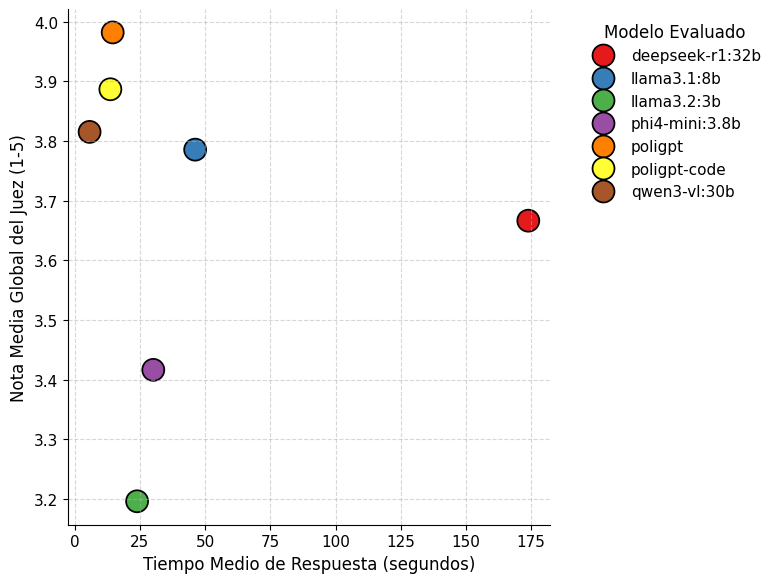

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

# Agrupamos los datos para pintar un único punto por modelo
agrupado = df.groupby('modelo_usado')[['tiempo_respuesta', 'nota_global_juez']].mean().reset_index()

# Pintar el gráfico
sns.scatterplot(
    data=agrupado, 
    x='tiempo_respuesta', 
    y='nota_global_juez', 
    hue='modelo_usado', 
    s=250, # Tamaño de los puntos grande
    palette='Set1',
    edgecolor='black', # Bordecito negro para resaltar
    ax=ax
)

ax.set_xlabel("Tiempo Medio de Respuesta (segundos)")
ax.set_ylabel("Nota Media Global del Juez (1-5)")

# Mover la leyenda fuera para no tapar los datos
ax.legend(title="Modelo Evaluado", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

plt.grid(True, linestyle='--', alpha=0.5) # Cuadrícula muy suave
plt.tight_layout()
plt.savefig("dispersion_calidad_tiempo.png", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_24246/354431855.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


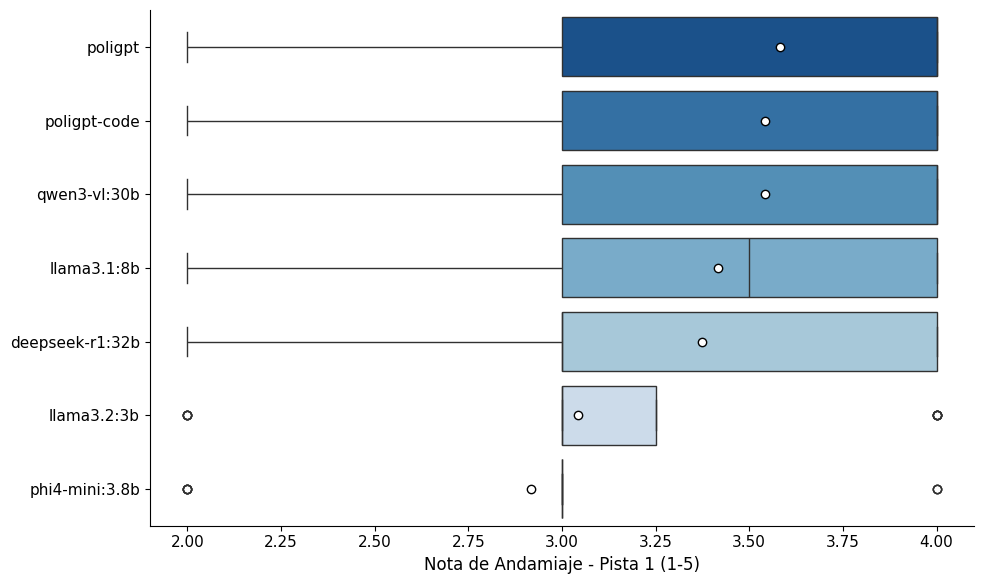

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

# Ordenamos los modelos de mejor a peor media para que el gráfico quede escalonado
orden_modelos = df.groupby('modelo_usado')['juez_p1_andamiaje'].mean().sort_values(ascending=False).index

sns.boxplot(
    data=df, 
    x='juez_p1_andamiaje', 
    y='modelo_usado', 
    order=orden_modelos,
    palette='Blues_r',
    ax=ax,
    showmeans=True, # Mostrar un punto para la media, no solo la mediana
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"}
)

ax.set_xlabel("Nota de Andamiaje - Pista 1 (1-5)")
ax.set_ylabel("") # Quitamos la etiqueta 'modelo_usado' porque es obvio por los nombres

plt.tight_layout()
plt.savefig("boxplot_andamiaje_p1.png", dpi=300, bbox_inches='tight')
plt.show()

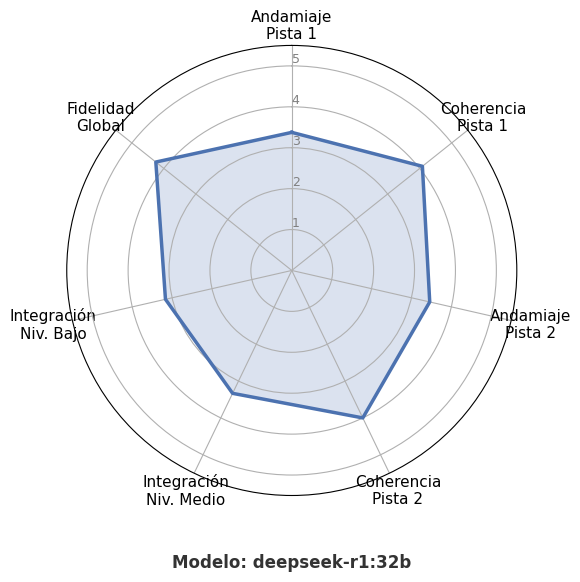

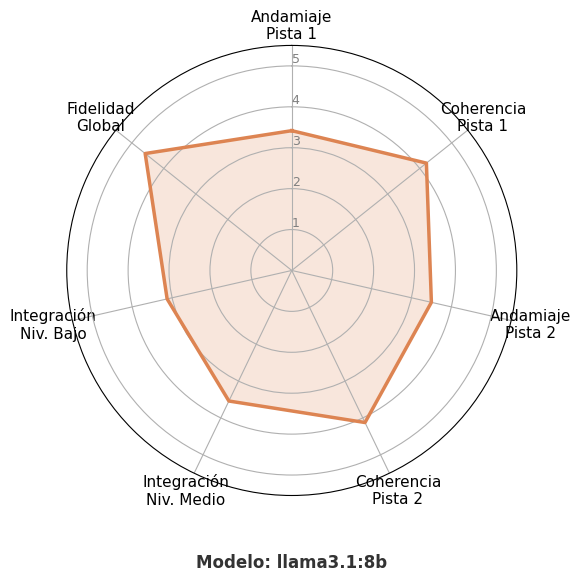

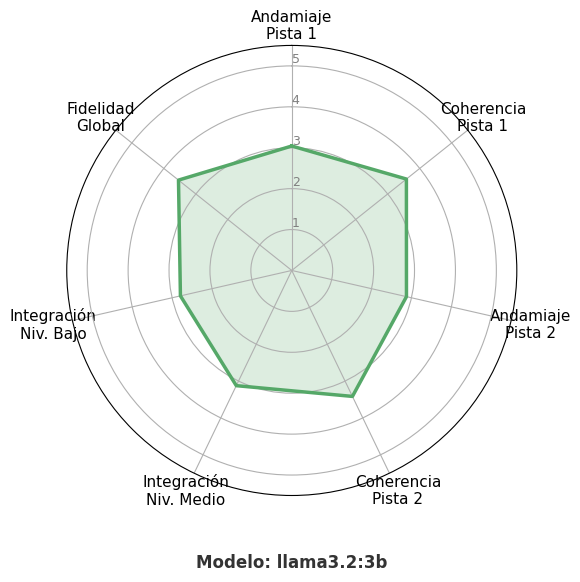

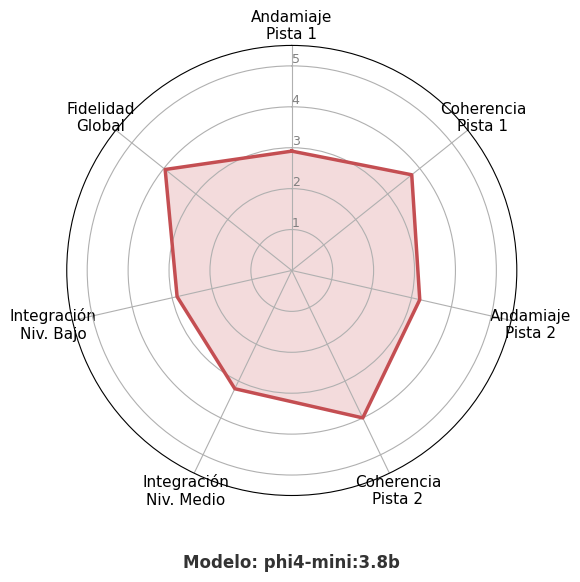

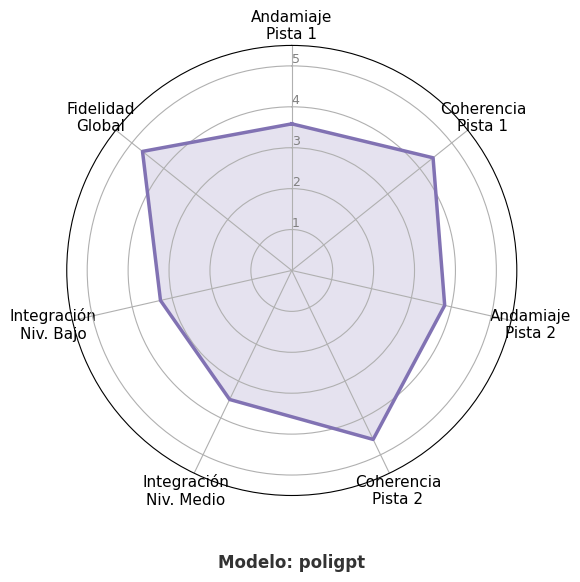

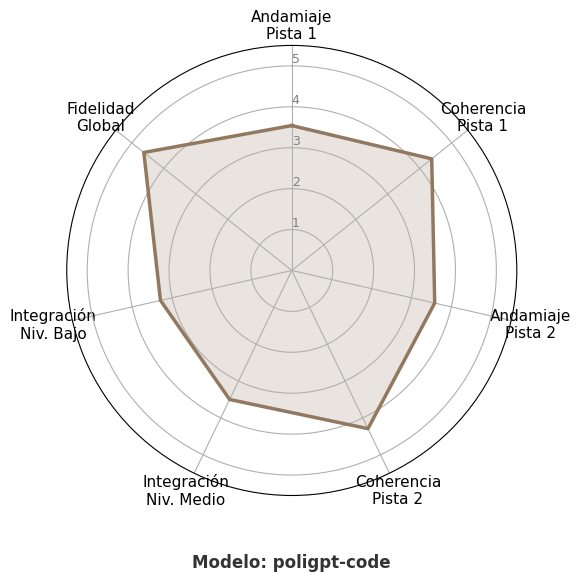

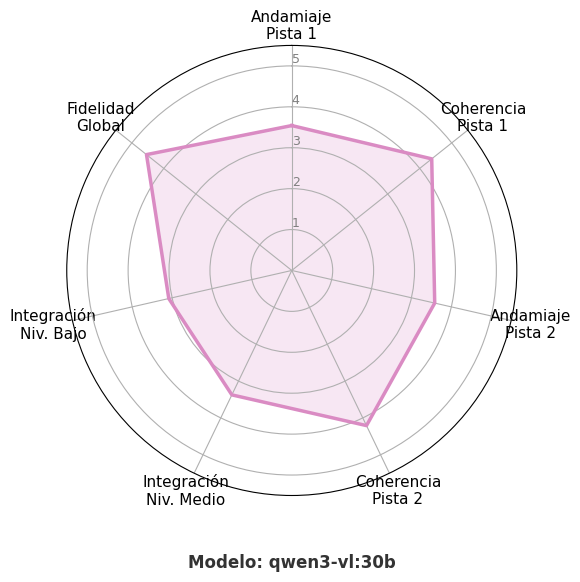

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from math import pi
import re

# 1. Preparar datos para radar (Medias agrupadas)
score_cols = [
    'juez_p1_andamiaje', 'juez_p1_coherencia', 
    'juez_p2_andamiaje', 'juez_p2_coherencia',
    'juez_medio_integracion', 'juez_bajo_integracion', 
    'juez_fidelidad'
]
radar_data = df.groupby('modelo_usado')[score_cols].mean().reset_index()

# 2. Etiquetas limpias con saltos de línea para los ejes
labels = [
    'Andamiaje\nPista 1', 'Coherencia\nPista 1', 
    'Andamiaje\nPista 2', 'Coherencia\nPista 2',
    'Integración\nNiv. Medio', 'Integración\nNiv. Bajo', 
    'Fidelidad\nGlobal'
]
num_vars = len(labels)

# 3. Calcular ángulos matemáticos para el polígono
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]  # Cerrar el círculo

# Paleta de colores para que cada modelo tenga un color distinto
colors = sns.color_palette("deep", len(radar_data))

# 4. Bucle: Crear un gráfico independiente por cada modelo
for i, row in radar_data.iterrows():
    modelo = row['modelo_usado']
    
    # Extraer los valores y cerrar el círculo
    values = row[score_cols].values.flatten().tolist()
    values += values[:1] 
    
    # Iniciar el lienzo polar individual (tamaño un poco más compacto)
    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.set_theta_offset(pi / 2) # Que la primera métrica empiece arriba
    ax.set_theta_direction(-1)  # Sentido horario
    
    # Dibujar los ejes y las guías circulares
    plt.xticks(angles[:-1], labels, size=11)
    ax.set_rlabel_position(0)
    plt.yticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5"], color="grey", size=9)
    plt.ylim(0, 5.5) # Dejar un poco de margen visual arriba
    
    # Pintar la línea y rellenar el área
    ax.plot(angles, values, linewidth=2.5, linestyle='solid', color=colors[i])
    ax.fill(angles, values, color=colors[i], alpha=0.2) # Relleno suave
    
    # Etiqueta discreta en la parte inferior para identificar la imagen (sin ser un título enorme)
    ax.text(0.5, -0.15, f"Modelo: {modelo}", size=12, ha='center', va='center', 
            transform=ax.transAxes, fontweight='bold', color='#333333')
    
    plt.tight_layout()
    
    # Limpiar el nombre del modelo para que sea un nombre de archivo válido
    nombre_seguro = re.sub(r'[^a-zA-Z0-9_]', '_', modelo)
    nombre_archivo = f"radar_{nombre_seguro}.png"
    
    # Guardar cada gráfico con altísima calidad
    plt.savefig(nombre_archivo, dpi=300, bbox_inches='tight')
    plt.show() # Mostrarlo en el Notebook

/tmp/ipykernel_24246/2470827381.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


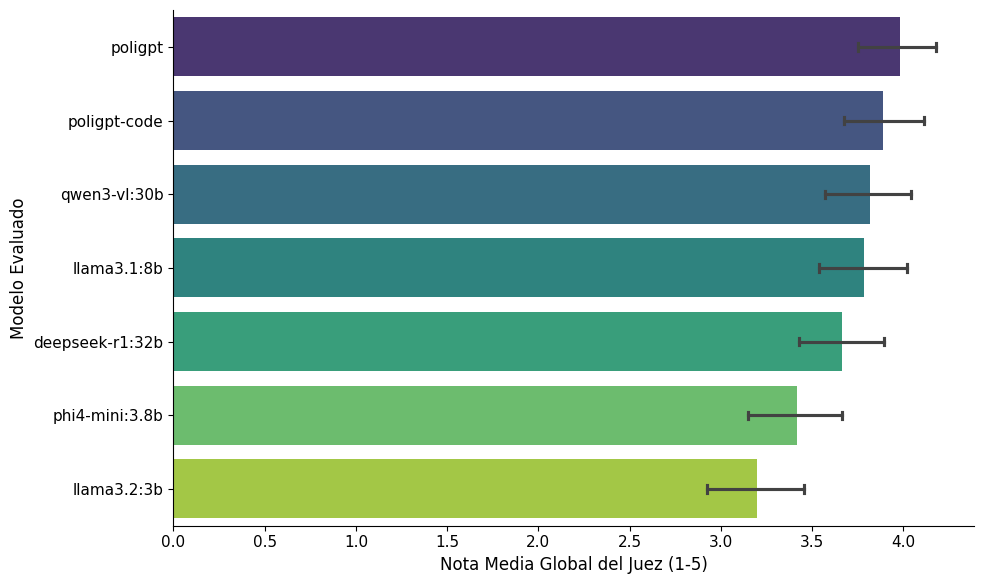

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

# Ordenar los modelos de mayor a menor nota
orden_modelos = df.groupby('modelo_usado')['nota_global_juez'].mean().sort_values(ascending=False).index

sns.barplot(
    data=df, 
    x='nota_global_juez', 
    y='modelo_usado', 
    order=orden_modelos, 
    palette='viridis', 
    errorbar='ci', # Muestra el intervalo de confianza (estabilidad)
    capsize=0.1,
    ax=ax
)

ax.set_xlabel("Nota Media Global del Juez (1-5)")
ax.set_ylabel("Modelo Evaluado")

plt.tight_layout()
plt.savefig("ranking_notas_juez.png", dpi=300, bbox_inches='tight')
plt.show()

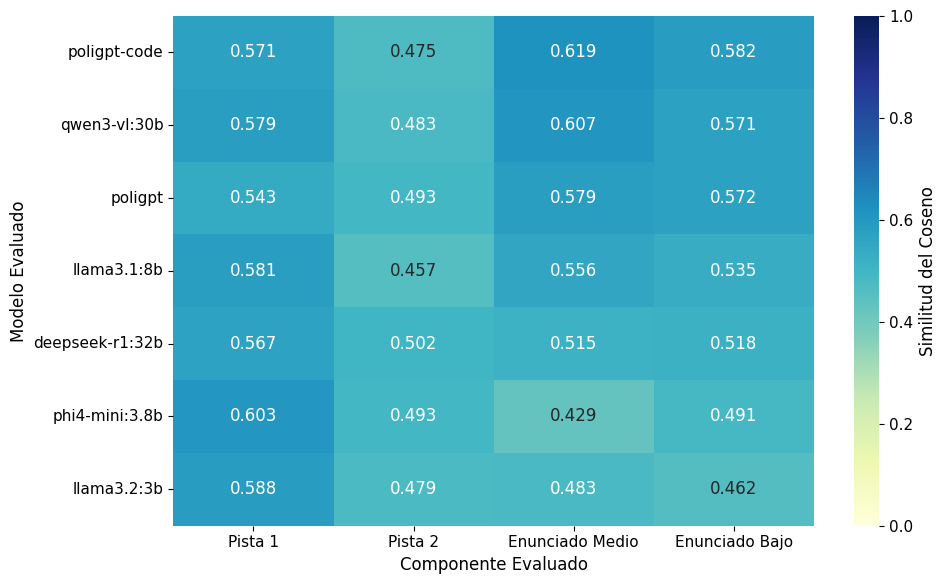

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

# Agrupar la media de similitud por cada columna para cada modelo
sim_data = df.groupby('modelo_usado')[sim_cols].mean()

# Limpiar los nombres de las columnas para que queden bonitos en el gráfico
sim_data.columns = ['Pista 1', 'Pista 2', 'Enunciado Medio', 'Enunciado Bajo']

# Ordenar por la media global de similitud de mayor a menor
sim_data['Media'] = sim_data.mean(axis=1)
sim_data = sim_data.sort_values('Media', ascending=False).drop(columns=['Media'])

# Crear el Heatmap
sns.heatmap(
    sim_data, 
    annot=True,        # Mostrar el número dentro de la celda
    fmt=".3f",         # 3 decimales
    cmap="YlGnBu",     # Paleta de amarillo (bajo) a azul oscuro (alto)
    vmin=0.0, vmax=1.0,# Forzar la escala de 0 a 1
    cbar_kws={'label': 'Similitud del Coseno'},
    ax=ax
)

ax.set_ylabel("Modelo Evaluado")
ax.set_xlabel("Componente Evaluado")

plt.tight_layout()
plt.savefig("heatmap_similitud.png", dpi=300, bbox_inches='tight')
plt.show()

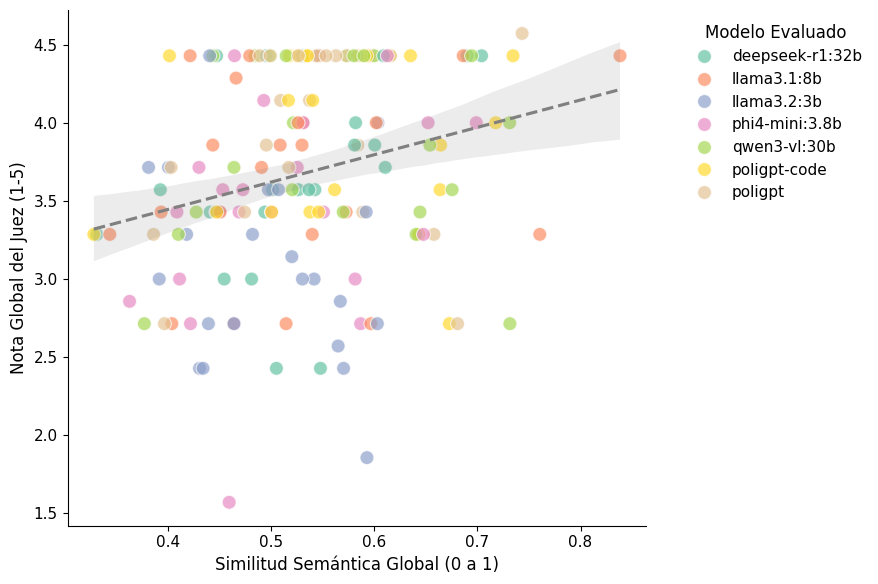

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))

# Usamos todos los datos (cada punto es una tarea de un modelo)
sns.scatterplot(
    data=df, 
    x='sim_global', 
    y='nota_global_juez', 
    hue='modelo_usado', 
    alpha=0.7, # Ligeramente transparentes para ver si se solapan
    s=100,
    palette='Set2',
    ax=ax
)

# Añadir una línea de tendencia general para guiar el ojo
sns.regplot(
    data=df, 
    x='sim_global', 
    y='nota_global_juez', 
    scatter=False, 
    color='gray', 
    line_kws={'linestyle':'--'},
    ax=ax
)

ax.set_xlabel("Similitud Semántica Global (0 a 1)")
ax.set_ylabel("Nota Global del Juez (1-5)")

ax.legend(title="Modelo Evaluado", bbox_to_anchor=(1.05, 1), loc='upper left', frameon=False)

plt.tight_layout()
plt.savefig("scatter_similitud_vs_juez.png", dpi=300, bbox_inches='tight')
plt.show()

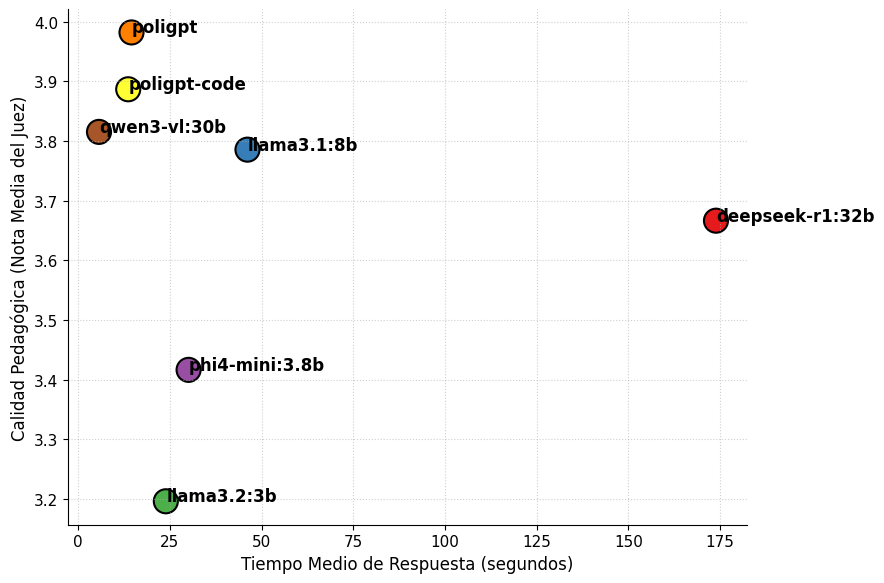

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))

# Agrupar las medias por modelo
agrupado = df.groupby('modelo_usado')[['tiempo_respuesta', 'nota_global_juez']].mean().reset_index()

sns.scatterplot(
    data=agrupado, 
    x='tiempo_respuesta', 
    y='nota_global_juez', 
    hue='modelo_usado', 
    s=300, # Puntos bien grandes
    palette='Set1',
    edgecolor='black',
    linewidth=1.5,
    ax=ax
)

# Añadir el nombre del modelo al lado de cada punto para que no haga falta mirar la leyenda
for i in range(agrupado.shape[0]):
    plt.text(
        agrupado['tiempo_respuesta'][i] + 0.1, # Desplazamiento X
        agrupado['nota_global_juez'][i],       # Altura Y
        agrupado['modelo_usado'][i], 
        horizontalalignment='left', 
        size='medium', color='black', weight='semibold'
    )

ax.set_xlabel("Tiempo Medio de Respuesta (segundos)")
ax.set_ylabel("Calidad Pedagógica (Nota Media del Juez)")

# Como hemos puesto los nombres en los puntos, ocultamos la leyenda para que quede más limpio
ax.get_legend().remove()

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig("scatter_calidad_vs_tiempo.png", dpi=300, bbox_inches='tight')
plt.show()

In [16]:
import pandas as pd
import numpy as np

# 1. Cargar los datos (Asegúrate de usar tu archivo más reciente, v2 si lo tienes)
df = pd.read_csv("resultados_finales_v2.csv") # Cambia el nombre si es necesario

# Asegurarse de que las columnas son numéricas
cols_numericas = [
    'juez_p1_andamiaje', 'juez_p1_coherencia', 'juez_p2_andamiaje', 'juez_p2_coherencia',
    'juez_medio_integracion', 'juez_bajo_integracion', 'juez_fidelidad',
    'sim_pista_1', 'sim_pista_2', 'sim_enunciado_medio', 'sim_enunciado_bajo',
    'tiempo_respuesta'
]
for col in cols_numericas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# ==========================================
# 2. CALCULAR MÉTRICAS COMPUESTAS POR FILA
# ==========================================

# Métrica 1: Calidad Pedagógica Global
columnas_juez = [
    'juez_p1_andamiaje', 'juez_p1_coherencia', 'juez_p2_andamiaje', 
    'juez_p2_coherencia', 'juez_medio_integracion', 'juez_bajo_integracion', 
    'juez_fidelidad'
]
df['calidad_juez'] = df[columnas_juez].mean(axis=1)

# Métrica 3: Integración de los enunciados
df['integracion_media'] = df[['juez_medio_integracion', 'juez_bajo_integracion']].mean(axis=1)

# Métrica 4: Similitud Semántica
df['sim_pistas'] = df[['sim_pista_1', 'sim_pista_2']].mean(axis=1)
df['sim_enunciados'] = df[['sim_enunciado_medio', 'sim_enunciado_bajo']].mean(axis=1)


# ==========================================
# 3. AGRUPAR POR MODELO Y CREAR LA TABLA
# ==========================================

tabla_criba = df.groupby('modelo_usado').agg(
    Calidad_Pedagogica_Global=('calidad_juez', 'mean'),
    Fidelidad=('juez_fidelidad', 'mean'),
    Integracion_Enunciados=('integracion_media', 'mean'),
    Sim_Pistas=('sim_pistas', 'mean'),
    Sim_Enunciados=('sim_enunciados', 'mean'),
    Tiempo_Medio_s=('tiempo_respuesta', 'mean')
).reset_index()


# ==========================================
# 4. CLASIFICACIÓN DEL TIEMPO (Lógica de Producción)
# ==========================================

def clasificar_velocidad(t):
    if pd.isna(t):
        return "Desconocido"
    elif t < 15:
        return "Rápido"
    elif t <= 60:
        return "Aceptable"
    else:
        return "Lento"

tabla_criba['Velocidad'] = tabla_criba['Tiempo_Medio_s'].apply(clasificar_velocidad)

# Ordenar de mejor a peor según la métrica principal
tabla_criba = tabla_criba.sort_values(by='Calidad_Pedagogica_Global', ascending=False)

# Redondear los decimales a 2 para que sea visualmente limpia en la memoria
columnas_a_redondear = ['Calidad_Pedagogica_Global', 'Fidelidad', 'Integracion_Enunciados', 'Sim_Pistas', 'Sim_Enunciados', 'Tiempo_Medio_s']
tabla_criba[columnas_a_redondear] = tabla_criba[columnas_a_redondear].round(2)

# Mostrar la tabla final
display(tabla_criba)

# Guardarla para la memoria del TFG
tabla_criba.to_csv("tabla_criba_tfg.csv", index=False, encoding="utf-8-sig")

,modelo_usado,Calidad_Pedagogica_Global,Fidelidad,Integracion_Enunciados,Sim_Pistas,Sim_Enunciados,Tiempo_Medio_s,Velocidad
4,poligpt,3.98,4.67,3.40,0.52,0.58,14.55,Rápido
5,poligpt-code,3.89,4.62,3.40,0.52,0.60,13.65,Rápido
6,qwen3-vl:30b,3.82,4.54,3.23,0.53,0.59,5.69,Rápido
1,llama3.1:8b,3.79,4.58,3.33,0.52,0.55,46.16,Aceptable
0,deepseek-r1:32b,3.67,4.25,3.25,0.53,0.52,173.88,Lento
3,phi4-mini:3.8b,3.42,3.96,3.04,0.55,0.46,30.11,Aceptable
2,llama3.2:3b,3.20,3.54,2.96,0.53,0.47,23.90,Aceptable
